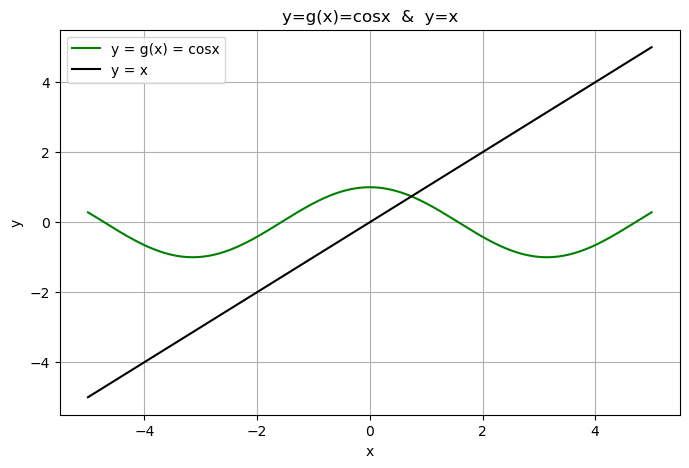

pk =  0.9999990244358875
Ck =  0.6736032990815267


In [16]:
import numpy as np
import matplotlib.pyplot as plt

#Prerequisites & function declerations
#Stopping tolerance and maximum iteration limits
tol = 1e-6
max_iter = 100

#We declare the function f(x) of the non-linear equation f(x) = cos(x) - x = 0
def f(x):
    return np.cos(x) - x

# We declare the rearrangement g(x) = cos(x)
def g(x):
    return np.cos(x)
 
# 1.Fixed-Point Iteration Method function
def FPI(x0):
    x_k = [x0] #We initialize a list to store all successive approximations x_k
    err = [] #We initialize a list to store all consecutive errors e_k for each iteration step
    for i in range(max_iter):        #We run the iteration loop up to max_iter
        x_next = g(x0)        #We calculate the next iterate: x_k+1 = g(x_k)
        x_k.append(x_next)
        err.append(np.abs(x_next - x0)) 

        #Convergence stopping criterion: |x_k+1 - x_k| < tol
        if np.abs(x_next - x0) < tol:
            break
        x0 = x_next #We update current estimate for the next step
        
    return x_k, err

# 2. matplotlib plot
x = np.linspace(-5,5,300)
plt.figure( figsize=(8,5) )
plt.plot(x, np.cos(x), 'g',label = 'y = g(x) = cosx')
plt.plot(x, x,'k', label = 'y = x')
plt.xlabel('x')
plt.ylabel('y')
plt.title('y=g(x)=cosx  &  y=x')
plt.grid()
plt.legend()
plt.show()

# 3. Asymptotic convergence estimation
#We extract the last three valid errors: e_{k-1}, e_k, and e_{k+1}
x_k, errors = FPI(0)

e_k2 = errors[- 1] #e_{k+1}
e_k1 = errors[- 2] #e_k
e_k  = errors[- 3] #e_{k-1}

p_k = (np.log(e_k2 / e_k1) / np.log(e_k1 / e_k)) #We calculate the asymptotic convergence rate (p_k):
C_k = e_k2 / ((e_k1)**p_k) #We calculate the asymptotic error constant (Ck)

#We print the experimental results
print('pk = ', p_k)
print('Ck = ', C_k)